In [1]:
import os
import random
import shutil

random.seed(42)

data_dir = '/kaggle/input/noisy-audio-mnist/'
output_dir = '/kaggle/working/'

noisy_files = []
clean_files = []

for folder in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder)
    if os.path.isdir(folder_path):
        for file in os.listdir(folder_path):
            if file.endswith('_noisy.wav'):
                noisy_files.append(os.path.join(folder_path, file))
                clean_filename = file.replace('_noisy.wav', '.wav')
                clean_files.append(os.path.join(folder_path, clean_filename))

paired_files = list(zip(noisy_files, clean_files))

random.shuffle(paired_files)

train_size = int(0.8 * len(paired_files))
val_size = int(0.1 * len(paired_files))

train_data = paired_files[:train_size]
val_data = paired_files[train_size:train_size + val_size]
test_data = paired_files[train_size + val_size:]

print(f"Training set size: {len(train_data)}")
print(f"Validation set size: {len(val_data)}")
print(f"Test set size: {len(test_data)}")

for split in ['train', 'val', 'test']:
    os.makedirs(os.path.join(output_dir, split), exist_ok=True)

def save_data_to_dir(data, split):
    for noisy, clean in data:
        noisy_dst = os.path.join(output_dir, split, os.path.basename(noisy))
        clean_dst = os.path.join(output_dir, split, os.path.basename(clean))
        shutil.copy(noisy, noisy_dst)
        shutil.copy(clean, clean_dst)

save_data_to_dir(train_data, 'train')
save_data_to_dir(val_data, 'val')
save_data_to_dir(test_data, 'test')


Training set size: 24000
Validation set size: 3000
Test set size: 3000


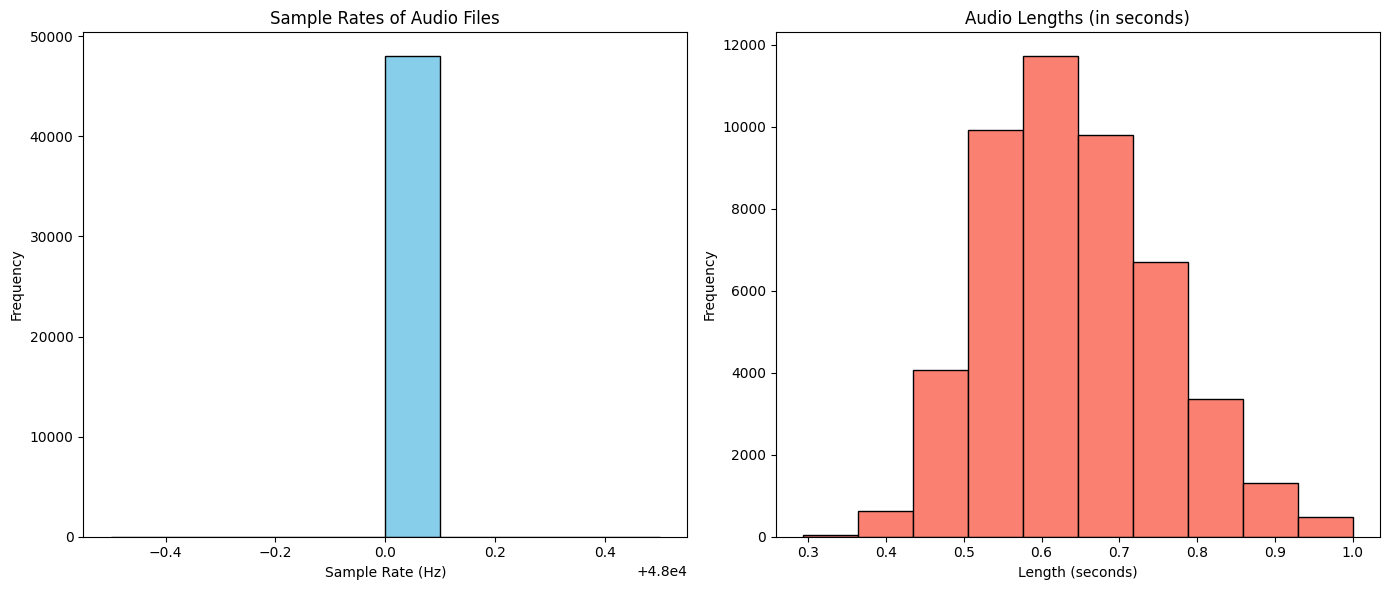

Sample Rates: [48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000, 48000

In [3]:
import librosa
import os
import numpy as np
import matplotlib.pyplot as plt

data_dir = '/kaggle/working/'

file_paths = []

for folder in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder)
    if os.path.isdir(folder_path):
        for file in os.listdir(folder_path):
            if file.endswith('.wav'):
                file_paths.append(os.path.join(folder_path, file))
    if len(file_paths) >= 10:  
        break

sample_rates = []
lengths = []

for file in file_paths:
    audio, sr = librosa.load(file, sr=None)  
    sample_rates.append(sr)
    lengths.append(len(audio) / sr)  

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.hist(sample_rates, bins=10, color='skyblue', edgecolor='black')
plt.title("Sample Rates of Audio Files")
plt.xlabel("Sample Rate (Hz)")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(lengths, bins=10, color='salmon', edgecolor='black')
plt.title("Audio Lengths (in seconds)")
plt.xlabel("Length (seconds)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Sample Rates: {sample_rates}")
print(f"Audio Lengths (seconds): {lengths}")


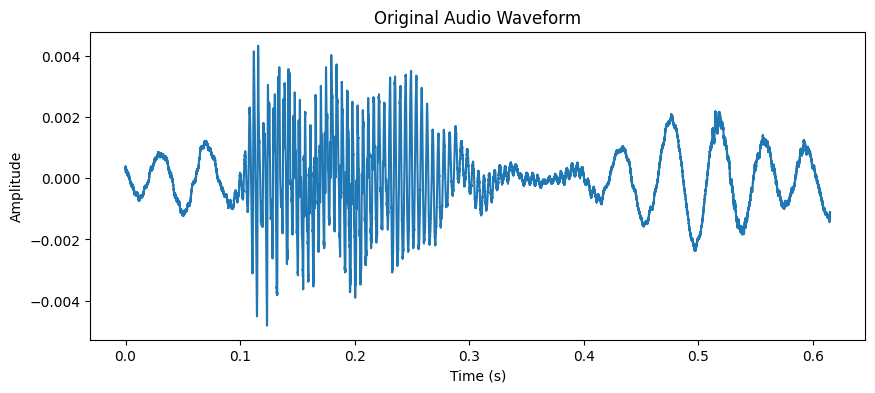

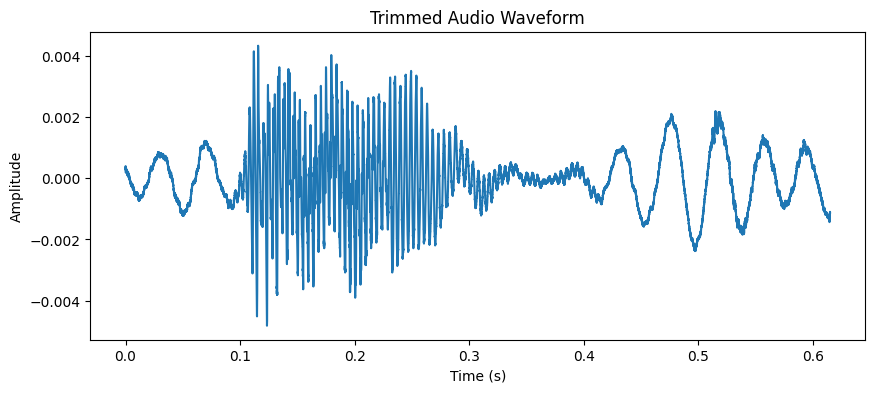

In [4]:
def plot_waveform(audio, sr, title="Audio Waveform"):
    plt.figure(figsize=(10, 4))
    plt.plot(np.linspace(0, len(audio) / sr, num=len(audio)), audio)
    plt.title(title)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.show()

audio, sr = librosa.load(file_paths[0], sr=None)
plot_waveform(audio, sr, "Original Audio Waveform")

audio_trimmed, _ = librosa.effects.trim(audio)
plot_waveform(audio_trimmed, sr, "Trimmed Audio Waveform")


In [5]:
audio, sr = librosa.load(file_paths[1], sr=None)

min_amplitude = np.min(audio)
max_amplitude = np.max(audio)

print(f"Amplitude Range of First Audio File: Min = {min_amplitude}, Max = {max_amplitude}")


Amplitude Range of First Audio File: Min = -0.11614990234375, Max = 0.0194091796875


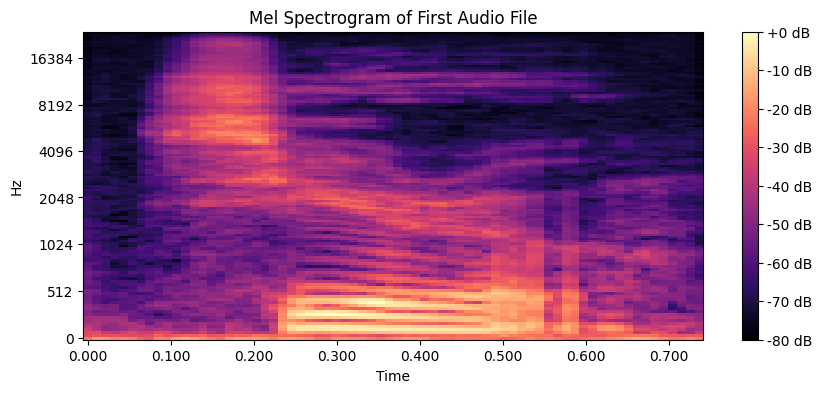

In [88]:
import librosa.display

def plot_mel_spectrogram(audio, sr, title="Mel Spectrogram"):
    mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128)
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(log_mel_spec, sr=sr, x_axis='time', y_axis='mel')
    plt.title(title)
    plt.colorbar(format='%+2.0f dB')
    plt.show()
audio, sr = librosa.load("/kaggle/working/test/0_01_13.wav", sr=None)

plot_mel_spectrogram(audio, sr, "Mel Spectrogram of First Audio File")


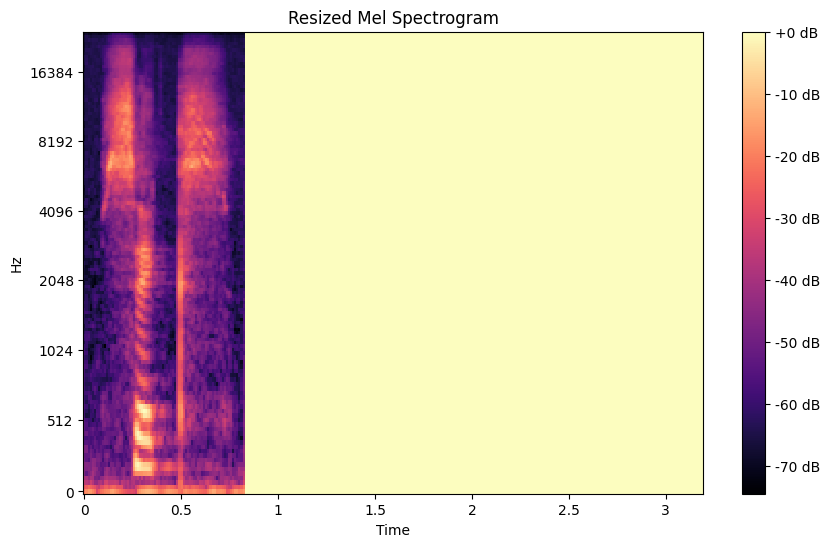

In [8]:
def pad_or_truncate_mel(mel_spec, target_length=300, target_n_mels=128):
    if mel_spec.shape[1] < target_length:
        mel_spec = np.pad(mel_spec, ((0, 0), (0, target_length - mel_spec.shape[1])), mode='constant')
    elif mel_spec.shape[1] > target_length:
        mel_spec = mel_spec[:, :target_length]
    
    if mel_spec.shape[0] < target_n_mels:
        mel_spec = np.pad(mel_spec, ((0, target_n_mels - mel_spec.shape[0]), (0, 0)), mode='constant')
    
    return mel_spec

fixed_size_mel_spec = pad_or_truncate_mel(mel_spec, target_length=300, target_n_mels=128)

plt.figure(figsize=(10, 6))
librosa.display.specshow(fixed_size_mel_spec, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title("Resized Mel Spectrogram")
plt.show()


In [4]:
import torch
import torch.nn as nn
class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super(UNet, self).__init__()
        
        self.enc1 = self.conv_block(in_channels, 64)
        self.enc2 = self.conv_block(64, 128)
        self.enc3 = self.conv_block(128, 256)
        self.enc4 = self.conv_block(256, 512)

        self.bottleneck = self.conv_block(512, 1024)

        self.dec4 = self.upconv_block(1024, 512)
        self.dec3 = self.upconv_block(1024, 256)
        self.dec2 = self.upconv_block(512, 128)
        self.dec1 = self.upconv_block(256, 64)

        self.reduce_channels = nn.Conv2d(128, 64, kernel_size=3, padding=1)

        self.final = nn.Conv2d(64, out_channels, kernel_size=1)
    
    def conv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    
    def upconv_block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    
    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(nn.MaxPool2d(2)(enc1))
        enc3 = self.enc3(nn.MaxPool2d(2)(enc2))
        enc4 = self.enc4(nn.MaxPool2d(2)(enc3))
    
        bottleneck = self.bottleneck(nn.MaxPool2d(2)(enc4))
    
        dec4 = self.dec4(bottleneck)
        dec4 = torch.cat((dec4, crop_tensor(enc4, dec4)), dim=1)
    
        dec3 = self.dec3(dec4)
        dec3 = torch.cat((dec3, crop_tensor(enc3, dec3)), dim=1)
    
        dec2 = self.dec2(dec3)
        dec2 = torch.cat((dec2, crop_tensor(enc2, dec2)), dim=1)
    
        dec1 = self.dec1(dec2)
        dec1 = torch.cat((dec1, crop_tensor(enc1, dec1)), dim=1)
    
        dec1 = self.reduce_channels(dec1)
    
        out = self.final(dec1)
    
        out = F.interpolate(out, size=(x.size(2), x.size(3)), mode='bilinear', align_corners=False)
    
        return out


In [5]:
def crop_tensor(tensor, target_tensor):
    _, _, h, w = tensor.size()
    _, _, target_h, target_w = target_tensor.size()

    crop_h = (h - target_h) // 2
    crop_w = (w - target_w) // 2

    return tensor[:, :, crop_h:crop_h + target_h, crop_w:crop_w + target_w]


In [6]:
import os
import torch
import librosa
import numpy as np
from scipy.ndimage import zoom
from torch.utils.data import Dataset

class AudioDenoisingDataset(Dataset):
    def __init__(self, data_dir, sr=48000, n_mels=128, hop_length=512, n_fft=2048, target_shape=(128, 100)):
        self.data_dir = data_dir
        self.files = [f for f in os.listdir(data_dir) if not f.endswith('_noisy.wav')]  
        self.sr = sr
        self.n_mels = n_mels
        self.hop_length = hop_length
        self.n_fft = n_fft
        self.target_shape = target_shape

    def __len__(self):
        return len(self.files)

    def generate_mel_spectrogram(self, audio_path):
        y, _ = librosa.load(audio_path, sr=self.sr)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=self.sr, n_mels=self.n_mels, 
                                                  hop_length=self.hop_length, n_fft=self.n_fft)
        mel_spec_log = librosa.power_to_db(mel_spec, ref=np.max)

        min_val, max_val = mel_spec_log.min(), mel_spec_log.max()
        mel_spec_norm = (mel_spec_log - min_val) / (max_val - min_val)

        mel_resized = zoom(mel_spec_norm, (self.target_shape[0] / mel_spec_norm.shape[0], 
                                           self.target_shape[1] / mel_spec_norm.shape[1]))
        return mel_resized, min_val, max_val

    def __getitem__(self, idx):
        clean_file = self.files[idx]
        noisy_file = clean_file.replace('.wav', '_noisy.wav')

        clean_path = os.path.join(self.data_dir, clean_file)
        noisy_path = os.path.join(self.data_dir, noisy_file)

        clean_spectrogram, clean_min, clean_max = self.generate_mel_spectrogram(clean_path)
        noisy_spectrogram, noisy_min, noisy_max = self.generate_mel_spectrogram(noisy_path)

        clean_tensor = torch.tensor(clean_spectrogram).float().unsqueeze(0)  
        noisy_tensor = torch.tensor(noisy_spectrogram).float().unsqueeze(0)  

        metadata = {
            "clean_min": clean_min, "clean_max": clean_max,
            "noisy_min": noisy_min, "noisy_max": noisy_max
        }

        return noisy_tensor, clean_tensor, metadata, clean_path, noisy_path


In [70]:
#train without reconstruct 

import time
from tqdm import tqdm
from torch.utils.data import DataLoader

model = UNet(in_channels=1, out_channels=1) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

loss_fn = nn.MSELoss()  
optimizer = optim.Adam(model.parameters(), lr=1e-4)

train_dataset = AudioDenoisingDataset(data_dir='/kaggle/working/train', target_shape=(128, 100))
val_dataset = AudioDenoisingDataset(data_dir='/kaggle/working/val', target_shape=(128, 100))
test_dataset = AudioDenoisingDataset(data_dir='/kaggle/working/test', target_shape=(128, 100))

batch_size = 64  
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

epochs = 1  
total_batches = len(train_loader)

for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    start_time = time.time()

    model.train()
    train_loss = 0.0
    with tqdm(total=total_batches, desc="Training", unit="batch") as pbar:
        for batch_idx, (noisy, clean) in enumerate(train_loader):
            noisy, clean = noisy.to(device), clean.to(device)

            output = model(noisy)

            loss = loss_fn(output, clean)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            pbar.set_postfix({"Batch Loss": loss.item()})
            pbar.update(1)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for noisy, clean in val_loader:
            noisy, clean = noisy.to(device), clean.to(device)

            output = model(noisy)

            loss = loss_fn(output, clean)
            val_loss += loss.item()

    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"Epoch {epoch + 1}/{epochs} completed in {elapsed_time:.2f} seconds")
    print(f"Train Loss: {train_loss / len(train_loader):.4f}")
    print(f"Validation Loss: {val_loss / len(val_loader):.4f}\n")

torch.save(model.state_dict(), "unet_audio_denoising.pth")
print("Model saved.")


Epoch 1/1


Training: 100%|██████████| 375/375 [13:10<00:00,  2.11s/batch, Batch Loss=0.00519]


Epoch 1/1 completed in 880.52 seconds
Train Loss: 0.0087
Validation Loss: 0.0054

Model saved.


In [72]:
torch.save(model.state_dict(), "/kaggle/working/unet_audio_denoising.pth")
print("Model saved.")

Model saved.


In [16]:
import matplotlib.pyplot as plt

def evaluate_model(model, test_loader, device, loss_fn):
    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for noisy, clean in test_loader:
            noisy, clean = noisy.to(device), clean.to(device)

            output = model(noisy)

            loss = loss_fn(output, clean)
            test_loss += loss.item()

    avg_test_loss = test_loss / len(test_loader)
    print(f"Average Test Loss: {avg_test_loss:.4f}")

def visualize_results(model, test_loader, device, num_samples=5):
    model.eval()
    with torch.no_grad():
        noisy, clean = next(iter(test_loader))
        noisy, clean = noisy.to(device), clean.to(device)

        output = model(noisy)

        fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5 * num_samples))
        for i in range(num_samples):
            axes[i, 0].imshow(noisy[i].cpu().squeeze(0), cmap='viridis', aspect='auto')
            axes[i, 0].set_title("Noisy Input")
            axes[i, 0].axis("off")

            axes[i, 1].imshow(output[i].cpu().squeeze(0), cmap='viridis', aspect='auto')
            axes[i, 1].set_title("Denoised Output")
            axes[i, 1].axis("off")

            axes[i, 2].imshow(clean[i].cpu().squeeze(0), cmap='viridis', aspect='auto')
            axes[i, 2].set_title("Clean Target")
            axes[i, 2].axis("off")

        plt.tight_layout()
        plt.show()

model.load_state_dict(torch.load("unet_audio_denoising.pth"))

evaluate_model(model, test_loader, device, loss_fn)

visualize_results(model, test_loader, device, num_samples=5)


In [14]:
import os
import soundfile as sf
import numpy as np

def calculate_snr(clean, output):

    noise = clean - output
    snr = 10 * torch.log10(torch.sum(clean ** 2) / torch.sum(noise ** 2))
    return snr.item()

def evaluate_with_snr(model, test_loader, device):

    model.eval()
    snr_improvement = 0.0
    with torch.no_grad():
        for noisy, clean in test_loader:
            noisy, clean = noisy.to(device), clean.to(device)

            output = model(noisy)

            batch_snr = [calculate_snr(clean[i], output[i]) for i in range(len(clean))]
            snr_improvement += sum(batch_snr)

    avg_snr_improvement = snr_improvement / (len(test_loader) * test_loader.batch_size)
    print(f"Average SNR Improvement: {avg_snr_improvement:.2f} dB")
    return avg_snr_improvement

def save_audio_files(model, test_loader, device, save_dir, num_samples=5, sample_rate=48000):

    os.makedirs(save_dir, exist_ok=True)

    model.eval()
    with torch.no_grad():
        noisy, clean = next(iter(test_loader))
        noisy, clean = noisy.to(device), clean.to(device)

        output = model(noisy)

        for i in range(num_samples):
            noisy_audio = noisy[i].cpu().squeeze().numpy()
            clean_audio = clean[i].cpu().squeeze().numpy()
            output_audio = output[i].cpu().squeeze().numpy()

            noisy_audio = noisy_audio / np.max(np.abs(noisy_audio))
            clean_audio = clean_audio / np.max(np.abs(clean_audio))
            output_audio = output_audio / np.max(np.abs(output_audio))

            sf.write(os.path.join(save_dir, f"sample_{i}_noisy.wav"), noisy_audio, sample_rate)
            sf.write(os.path.join(save_dir, f"sample_{i}_clean.wav"), clean_audio, sample_rate)
            sf.write(os.path.join(save_dir, f"sample_{i}_output.wav"), output_audio, sample_rate)

        print(f"Audio files saved to {save_dir}")

model.load_state_dict(torch.load("unet_audio_denoising.pth"))

evaluate_with_snr(model, test_loader, device)

save_audio_files(model, test_loader, device, save_dir="/kaggle/working/", num_samples=5)


/tmp/ipykernel_30/1453191795.py:90: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("unet_audio_denoising.pth"))


FileNotFoundError: [Errno 2] No such file or directory: 'unet_audio_denoising.pth'

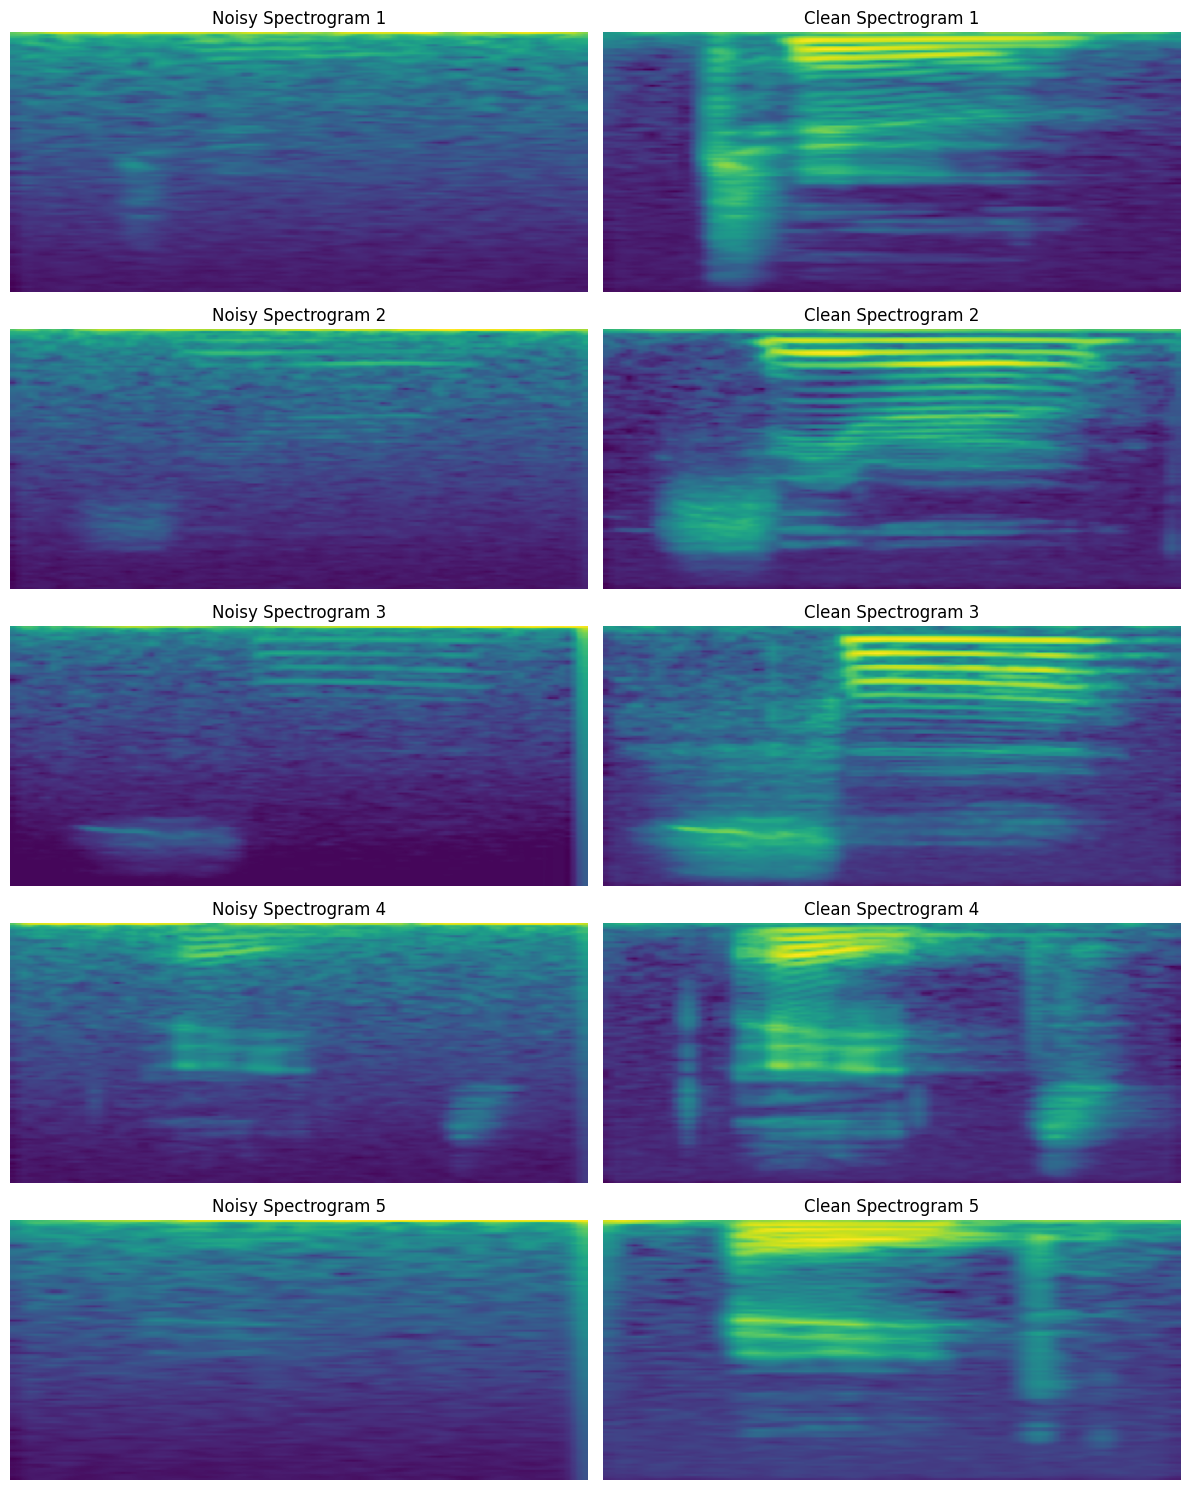

In [80]:
import matplotlib.pyplot as plt

def visualize_spectrograms(test_loader, num_samples=5):
    noisy, clean = next(iter(test_loader))

    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 3 * num_samples))
    for i in range(num_samples):
        axes[i, 0].imshow(noisy[i].squeeze().numpy(), cmap='viridis', aspect='auto')
        axes[i, 0].set_title(f"Noisy Spectrogram {i+1}")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(clean[i].squeeze().numpy(), cmap='viridis', aspect='auto')
        axes[i, 1].set_title(f"Clean Spectrogram {i+1}")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

visualize_spectrograms(test_loader)


In [81]:
import librosa
import librosa.display
import soundfile as sf

noisy, clean = next(iter(test_loader))
clean_mel = clean[0].squeeze().numpy()

reconstructed_audio = librosa.feature.inverse.mel_to_audio(clean_mel, sr=48000, n_fft=2048, hop_length=512, power=2.0)

sf.write("/kaggle/working/test_clean_reconstructed.wav", reconstructed_audio, 48000)
print("Reconstructed clean audio saved.")


Reconstructed clean audio saved.


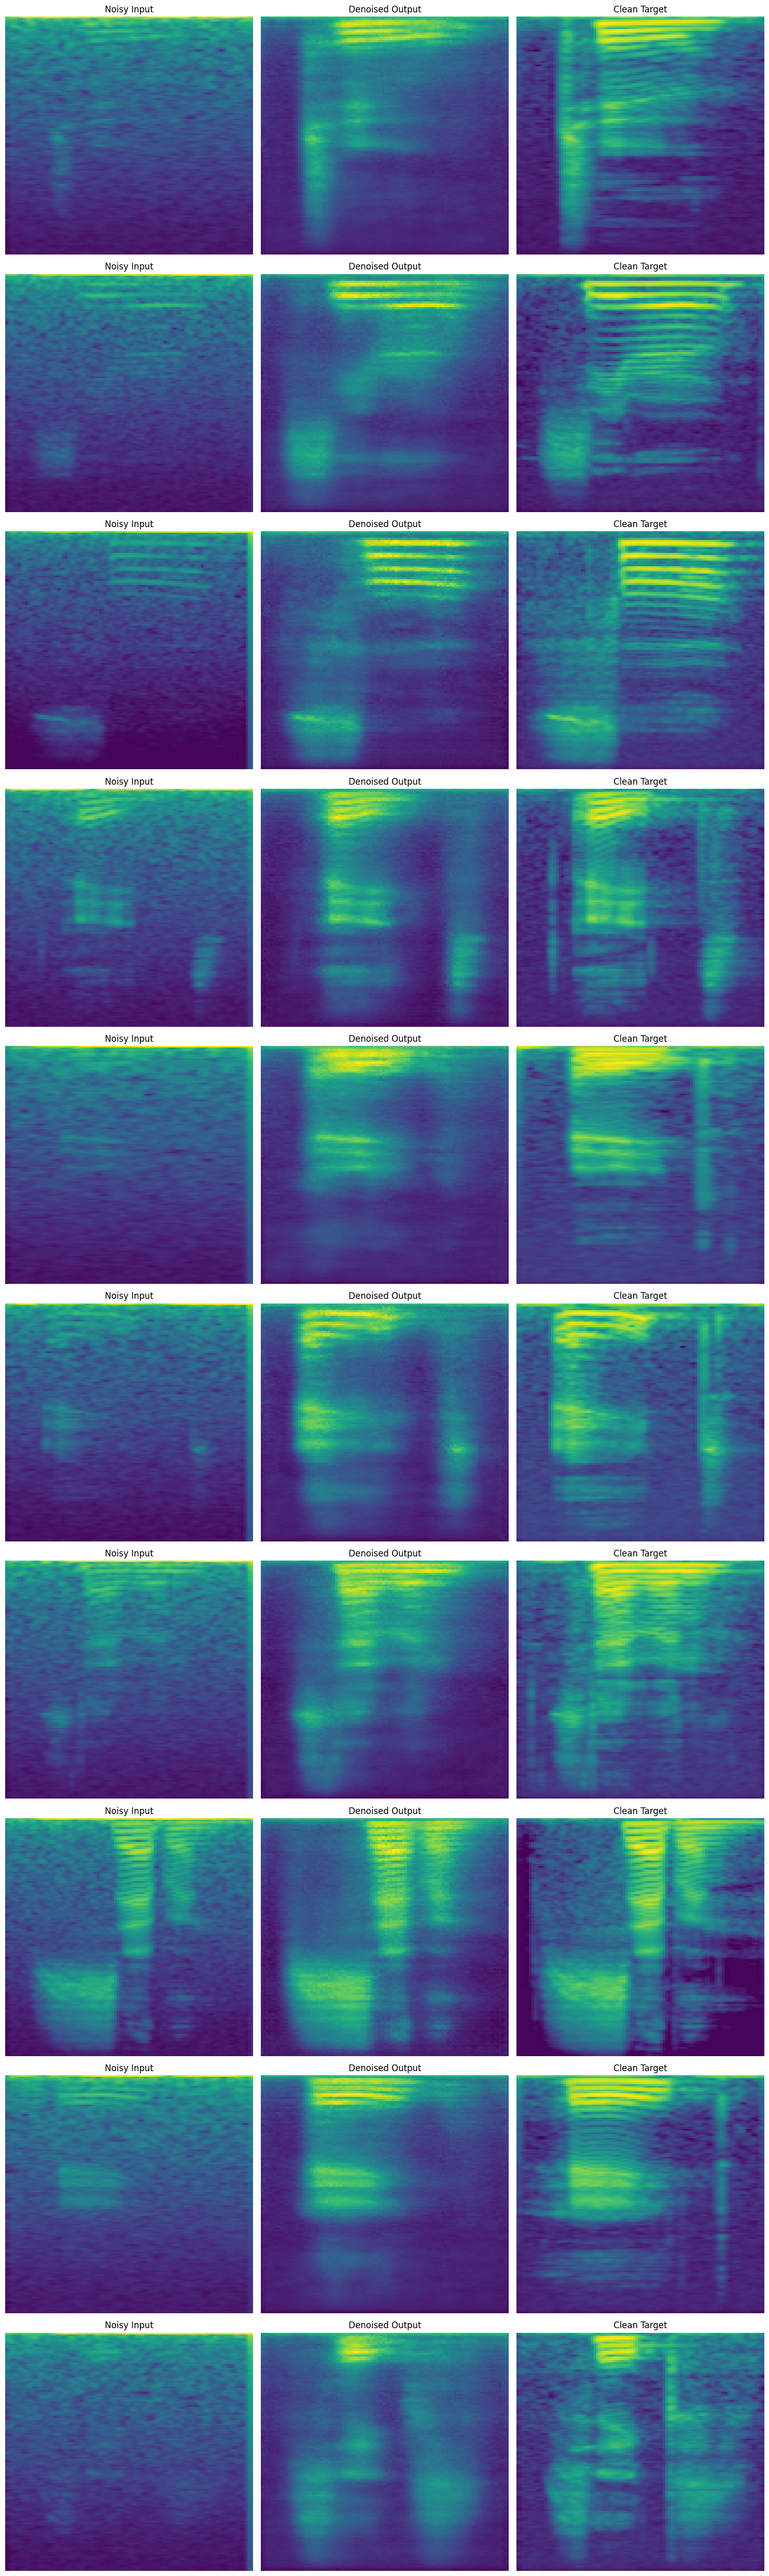

In [83]:
def visualize_model_outputs(model, test_loader, device, num_samples=10):
    model.eval()
    noisy, clean = next(iter(test_loader))
    noisy, clean = noisy.to(device), clean.to(device)

    with torch.no_grad():
        output = model(noisy)

    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5 * num_samples))
    for i in range(num_samples):
        axes[i, 0].imshow(noisy[i].cpu().squeeze().numpy(), cmap='viridis', aspect='auto')
        axes[i, 0].set_title("Noisy Input")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(output[i].cpu().squeeze().numpy(), cmap='viridis', aspect='auto')
        axes[i, 1].set_title("Denoised Output")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(clean[i].cpu().squeeze().numpy(), cmap='viridis', aspect='auto')
        axes[i, 2].set_title("Clean Target")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()

visualize_model_outputs(model, test_loader, device)


In [84]:
noisy, clean = next(iter(test_loader))
print("Noisy Spectrogram Range:", noisy.min().item(), noisy.max().item())
print("Clean Spectrogram Range:", clean.min().item(), clean.max().item())

model.eval()
with torch.no_grad():
    output = model(noisy.to(device))
print("Model Output Spectrogram Range:", output.min().item(), output.max().item())


Noisy Spectrogram Range: -0.03324688971042633 1.0113173723220825
Clean Spectrogram Range: -0.024047527462244034 1.0054872035980225
Model Output Spectrogram Range: -0.12740804255008698 1.1520010232925415


In [90]:
noisy, clean = next(iter(test_loader))
noisy_sample = noisy[0].to(device).unsqueeze(0)

model.eval()
with torch.no_grad():
    output = model(noisy_sample)

output_mel = output.squeeze().cpu().numpy()
reconstructed_audio = librosa.feature.inverse.mel_to_audio(output_mel, sr=48000, n_fft=2048, hop_length=512, power=2.0)

sf.write("/kaggle/working/manual_test_output.wav", reconstructed_audio, 48000)
print("Manual test output saved.")


tensor([[[[ 7.5457e-01,  7.7988e-01,  8.1790e-01,  ...,  8.9424e-01,
            8.4538e-01,  8.1520e-01],
          [ 7.2077e-01,  7.2483e-01,  7.2989e-01,  ...,  7.9467e-01,
            7.7411e-01,  7.4625e-01],
          [ 6.6431e-01,  6.5752e-01,  6.4562e-01,  ...,  7.2977e-01,
            7.1559e-01,  7.1049e-01],
          ...,
          [ 2.6539e-02,  4.9471e-02,  8.1278e-02,  ...,  6.6926e-02,
            5.4478e-02,  4.6091e-02],
          [-3.2879e-19,  1.8467e-02,  4.6249e-02,  ...,  7.0728e-02,
            6.1605e-02,  5.6049e-02],
          [ 9.0701e-03,  2.6915e-02,  5.5321e-02,  ...,  5.7048e-02,
            6.8632e-02,  7.6070e-02]]],


        [[[ 7.2349e-01,  7.6680e-01,  7.9527e-01,  ...,  8.6980e-01,
            8.5882e-01,  8.6451e-01],
          [ 6.2727e-01,  6.3746e-01,  6.3600e-01,  ...,  6.3836e-01,
            7.0707e-01,  7.5916e-01],
          [ 6.1093e-01,  6.1199e-01,  6.0886e-01,  ...,  5.7810e-01,
            6.0964e-01,  6.8212e-01],
          ...,
   

In [86]:
def calculate_baseline_snr(test_loader, device):
    total_snr = 0.0
    num_samples = 0

    with torch.no_grad():
        for noisy, clean in test_loader:
            noisy, clean = noisy.to(device), clean.to(device)

            batch_snr = []
            for i in range(len(clean)):
                noise = clean[i] - noisy[i]
                snr = 10 * torch.log10(torch.sum(clean[i] ** 2) / torch.sum(noise ** 2))
                batch_snr.append(snr.item())

            total_snr += sum(batch_snr)
            num_samples += len(batch_snr)

    avg_baseline_snr = total_snr / num_samples
    print(f"Average Baseline SNR (Noisy vs. Clean): {avg_baseline_snr:.2f} dB")
    return avg_baseline_snr


In [87]:
baseline_snr = calculate_baseline_snr(test_loader, device)

model_snr = evaluate_with_snr(model, test_loader, device)

print(f"Baseline SNR: {baseline_snr:.2f} dB")
print(f"Model SNR Improvement: {model_snr:.2f} dB")

Average Baseline SNR (Noisy vs. Clean): 7.67 dB
Average SNR Improvement: 14.48 dB
Baseline SNR: 7.67 dB
Model SNR Improvement: 14.48 dB


In [93]:
from tqdm import tqdm
import time

train_dataset = AudioDenoisingDataset(data_dir='/kaggle/working/train', target_shape=(128, 100))
val_dataset = AudioDenoisingDataset(data_dir='/kaggle/working/val', target_shape=(128, 100))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

model = UNet(in_channels=1, out_channels=1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

epochs = 1

for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    start_time = time.time()

    with tqdm(total=len(train_loader), desc=f"Epoch {epoch + 1}/{epochs}", unit="batch") as pbar:
        for noisy, clean, _ in train_loader:
            noisy, clean = noisy.to(device), clean.to(device)

            output = model(noisy)

            loss = loss_fn(output, clean)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            pbar.set_postfix({"Train Loss": loss.item()})
            pbar.update(1)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for noisy, clean, _ in val_loader:
            noisy, clean = noisy.to(device), clean.to(device)

            output = model(noisy)

            loss = loss_fn(output, clean)
            val_loss += loss.item()

    elapsed_time = time.time() - start_time
    print(f"Epoch {epoch + 1}/{epochs} - Train Loss: {train_loss / len(train_loader):.4f}, "
          f"Val Loss: {val_loss / len(val_loader):.4f}, Time: {elapsed_time:.2f}s")

torch.save(model.state_dict(), "unet_audio_denoising_reconstructable.pth")
print("New model saved as 'unet_audio_denoising_reconstructable.pth'.")


Epoch 1/1: 100%|██████████| 375/375 [12:59<00:00,  2.08s/batch, Train Loss=0.0053] 


Epoch 1/1 - Train Loss: 0.0072, Val Loss: 0.0052, Time: 871.32s
New model saved as 'unet_audio_denoising_reconstructable.pth'.


In [10]:
print(device)

cuda


In [96]:
baseline_snr = calculate_baseline_snr(test_loader, device)

model_snr = evaluate_with_snr(model, test_loader, device)

print(f"Baseline SNR: {baseline_snr:.2f} dB")
print(f"Model SNR Improvement: {model_snr:.2f} dB")

Average Baseline SNR (Noisy vs. Clean): 7.67 dB
Average SNR Improvement: 14.66 dB
Baseline SNR: 7.67 dB
Model SNR Improvement: 14.66 dB


In [102]:
test_dataset = AudioDenoisingDataset(data_dir='/kaggle/working/test', target_shape=(128, 100))
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [103]:
noisy, clean, metadata = next(iter(test_loader))
print("Noisy Shape:", noisy.shape)
print("Clean Shape:", clean.shape)
print("Metadata Keys:", metadata.keys())

Noisy Shape: torch.Size([16, 1, 128, 100])
Clean Shape: torch.Size([16, 1, 128, 100])
Metadata Keys: dict_keys(['clean_min', 'clean_max', 'noisy_min', 'noisy_max'])


In [106]:
import os
import librosa
import soundfile as sf
import numpy as np
import torch

def reconstruct_audio_from_spectrogram(spectrogram, min_val, max_val, sr=48000, n_fft=2048, hop_length=512):

    min_val = min_val.item() if isinstance(min_val, torch.Tensor) else min_val
    max_val = max_val.item() if isinstance(max_val, torch.Tensor) else max_val

    denormalized_spectrogram = spectrogram * (max_val - min_val) + min_val
    
    linear_spectrogram = librosa.db_to_power(denormalized_spectrogram)
    
    audio = librosa.feature.inverse.mel_to_audio(linear_spectrogram, sr=sr, n_fft=n_fft, hop_length=hop_length)
    return audio


def save_test_reconstructions(model, test_loader, device, save_dir, num_samples=5, sr=48000):
    os.makedirs(save_dir, exist_ok=True)
    
    model.eval()
    with torch.no_grad():
        for batch_idx, (noisy, clean, metadata) in enumerate(test_loader):
            noisy, clean = noisy.to(device), clean.to(device)
            output = model(noisy)

            for i in range(min(num_samples, noisy.size(0))):
                noisy_spectrogram = noisy[i].cpu().squeeze().numpy()
                clean_spectrogram = clean[i].cpu().squeeze().numpy()
                output_spectrogram = output[i].cpu().squeeze().numpy()
                
                clean_min, clean_max = metadata["clean_min"][i], metadata["clean_max"][i]
                noisy_min, noisy_max = metadata["noisy_min"][i], metadata["noisy_max"][i]
                
                noisy_audio = reconstruct_audio_from_spectrogram(noisy_spectrogram, noisy_min, noisy_max, sr)
                clean_audio = reconstruct_audio_from_spectrogram(clean_spectrogram, clean_min, clean_max, sr)
                output_audio = reconstruct_audio_from_spectrogram(output_spectrogram, clean_min, clean_max, sr)

                sf.write(os.path.join(save_dir, f"sample_{batch_idx * test_loader.batch_size + i}_noisy.wav"), noisy_audio, sr)
                sf.write(os.path.join(save_dir, f"sample_{batch_idx * test_loader.batch_size + i}_clean.wav"), clean_audio, sr)
                sf.write(os.path.join(save_dir, f"sample_{batch_idx * test_loader.batch_size + i}_output.wav"), output_audio, sr)

            if batch_idx + 1 >= (num_samples // test_loader.batch_size):
                break

    print(f"Audio files saved to {save_dir}")

model = UNet(in_channels=1, out_channels=1) 
model.load_state_dict(torch.load("unet_audio_denoising_reconstructable.pth"))
model = model.to(device)

save_test_reconstructions(model, test_loader, device, save_dir="/kaggle/working/reconstructed_audio", num_samples=5)


/tmp/ipykernel_30/4054378785.py:84: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("unet_audio_denoising_reconstructable.pth"))


Audio files saved to /kaggle/working/reconstructed_audio


In [111]:
test_dataset = AudioDenoisingDataset(data_dir='/kaggle/working/test', target_shape=(128, 100))
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [112]:
def save_test_reconstructions_with_paths(
    model, test_loader, device, save_dir, num_samples=5, sr=48000
):
    os.makedirs(save_dir, exist_ok=True)

    model.eval()
    with torch.no_grad():
        total_processed = 0
        for batch_idx, (noisy, clean, metadata, clean_path, noisy_path) in enumerate(test_loader):
            noisy, clean = noisy.to(device), clean.to(device)
            output = model(noisy)

            for i in range(noisy.size(0)):
                if total_processed >= num_samples:
                    return

                noisy_spectrogram = noisy[i].cpu().squeeze().numpy()
                clean_spectrogram = clean[i].cpu().squeeze().numpy()
                output_spectrogram = output[i].cpu().squeeze().numpy()

                clean_min, clean_max = metadata["clean_min"][i], metadata["clean_max"][i]
                noisy_min, noisy_max = metadata["noisy_min"][i], metadata["noisy_max"][i]

                noisy_audio = reconstruct_audio_from_spectrogram(
                    noisy_spectrogram, noisy_min, noisy_max, sr
                )
                clean_audio = reconstruct_audio_from_spectrogram(
                    clean_spectrogram, clean_min, clean_max, sr
                )
                output_audio = reconstruct_audio_from_spectrogram(
                    output_spectrogram, clean_min, clean_max, sr
                )

                noisy_save_path = os.path.join(save_dir, f"sample_{total_processed}_noisy.wav")
                clean_save_path = os.path.join(save_dir, f"sample_{total_processed}_clean.wav")
                output_save_path = os.path.join(save_dir, f"sample_{total_processed}_output.wav")

                sf.write(noisy_save_path, noisy_audio, sr)
                sf.write(clean_save_path, clean_audio, sr)
                sf.write(output_save_path, output_audio, sr)

                print(f"Sample {total_processed}:")
                print(f"  Original Noisy File: {noisy_path[i]}")
                print(f"  Original Clean File: {clean_path[i]}")
                print(f"  Saved Noisy Audio: {noisy_save_path}")
                print(f"  Saved Clean Audio: {clean_save_path}")
                print(f"  Saved Output Audio: {output_save_path}")
                print("-" * 50)

                total_processed += 1

save_test_reconstructions_with_paths(
    model=model,
    test_loader=test_loader,
    device=device,
    save_dir="/kaggle/working/reconstructed_audio",
    num_samples=5,
)


Sample 0:
  Original Noisy File: /kaggle/working/test/2_02_7_noisy.wav
  Original Clean File: /kaggle/working/test/2_02_7.wav
  Saved Noisy Audio: /kaggle/working/reconstructed_audio/sample_0_noisy.wav
  Saved Clean Audio: /kaggle/working/reconstructed_audio/sample_0_clean.wav
  Saved Output Audio: /kaggle/working/reconstructed_audio/sample_0_output.wav
--------------------------------------------------
Sample 1:
  Original Noisy File: /kaggle/working/test/0_36_22_noisy.wav
  Original Clean File: /kaggle/working/test/0_36_22.wav
  Saved Noisy Audio: /kaggle/working/reconstructed_audio/sample_1_noisy.wav
  Saved Clean Audio: /kaggle/working/reconstructed_audio/sample_1_clean.wav
  Saved Output Audio: /kaggle/working/reconstructed_audio/sample_1_output.wav
--------------------------------------------------
Sample 2:
  Original Noisy File: /kaggle/working/test/4_58_23_noisy.wav
  Original Clean File: /kaggle/working/test/4_58_23.wav
  Saved Noisy Audio: /kaggle/working/reconstructed_audio